<a href="https://colab.research.google.com/github/TildeSkar/Applied-Deep-Learning---Physics---exrecises/blob/main/Exercise_6_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 6.3: Neural Networks in Keras

In [176]:
import numpy as np
import matplotlib.pyplot as plt

# See https://keras.io/
# for extennsive documentation
import tensorflow as tf
from tensorflow import keras

from keras.models import Sequential
from keras.layers import Dense

plt.style.use("seaborn-v0_8")

Let us visit the problem of wine quality prediction previously encountered one final time. After linear regression and a self-made network, we can now explore the comfort provided by the Keras library.

In [177]:
# The code snippet below is responsible for downloading the dataset to
# Google. You can directly download the file using the link
# if you work with a local anaconda setup
!wget -nc https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv --no-check-certificate

File ‘winequality-white.csv’ already there; not retrieving.



In [178]:
# load all examples from the file
data = np.genfromtxt("winequality-white.csv", delimiter=";", skip_header=1)

print(f"{data.shape = } \n")

# Prepare for proper training
rng = np.random.default_rng(1234)
rng.shuffle(data)  # randomly sort examples

# take the first 3000 examples for training
# (remember array slicing from last week)
X_train = data[:3000, :11]  # all features except last column
y_train = data[:3000, 11]  # quality column

# and the remaining examples for testing
X_test = data[3000:, :11]  # all features except last column
y_test = data[3000:, 11]  # quality column

print("First example:")
print("Features:", X_train[0])
print("Quality:", y_train[0])

data.shape = (4898, 12) 

First example:
Features: [6.8000e+00 1.9000e-01 7.1000e-01 1.7500e+01 4.2000e-02 2.1000e+01
 1.1400e+02 9.9784e-01 2.8500e+00 5.0000e-01 9.5000e+00]
Quality: 6.0


Below is the simple network from exercise 4.1 implemented using Keras. In addition to the network we define the loss function and optimiser.

In [179]:
# See: https://keras.io/api/models/sequential/ and
# https://keras.io/api/layers/core_layers/dense/
# We can use the Sequential class to very easiliy
# build a simple architecture

# Specifications of the network
nb_nodes = 30
nb_layers = 3 # two more layers 1+2=3


model = Sequential()

# First layer
model.add(Dense(nb_nodes, input_dim=11, activation='relu'))

# Adds more layers
for i in range(1, nb_layers):
      model.add(Dense(nb_nodes, activation='relu')) # adds more layers

# Final layer
model.add(Dense(1, activation='linear'))


# Set loss function and optimiser algorithm
optimizer_1 = 'sgd'
optimizer_2 = keras.optimizers.SGD(learning_rate=0.00001, momentum=0.9) #creating optimizer with momentum
optimizer_3 = 'adam'
model.compile(
    loss='mse',  # mean squared error
    optimizer= optimizer_3 # stochastic gradient descent with momentum
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Training and evaluation below

The code below trains the network for 20 epochs using the loss function and optimiser defined above. Each example is individually passed to the network

In [180]:
history = model.fit(X_train, y_train,
                    validation_data=(X_test, y_test),
                    epochs=20, batch_size=5)


Epoch 1/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 3.3728 - val_loss: 1.6252
Epoch 2/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7968 - val_loss: 0.6093
Epoch 3/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.7354 - val_loss: 0.7167
Epoch 4/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6908 - val_loss: 0.6104
Epoch 5/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7309 - val_loss: 1.0008
Epoch 6/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7711 - val_loss: 0.7594
Epoch 7/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6620 - val_loss: 0.5922
Epoch 8/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6768 - val_loss: 0.6473
Epoch 9/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6640 - val_loss: 0.5847
Epoch 10/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6782 - val_loss: 0.5698
Epoch 11/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6490 - val_loss: 0.6920
Epoch 12/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step

In [181]:
# The history object returned by the model training above
# contains the values of the loss function (the mean-squared-error)
# at different epochs
# We discard the first epoch as the loss value is very high,
# obscuring the rest of the distribution
train_loss = history.history["loss"][1:]
test_loss = history.history["val_loss"][1:]

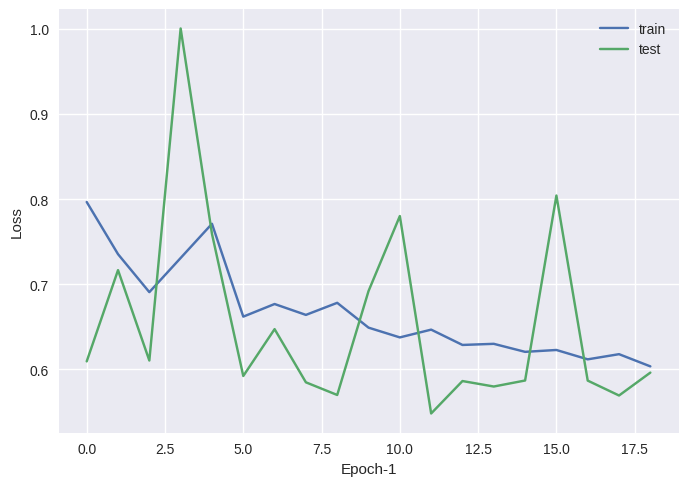

In [182]:
# Prepare and plot loss over time
plt.plot(train_loss,label="train")
plt.plot(test_loss,label="test")
plt.legend()
plt.xlabel("Epoch-1")
plt.ylabel("Loss")
plt.show()

60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  
Correlation coefficient: 0.5346881105189426


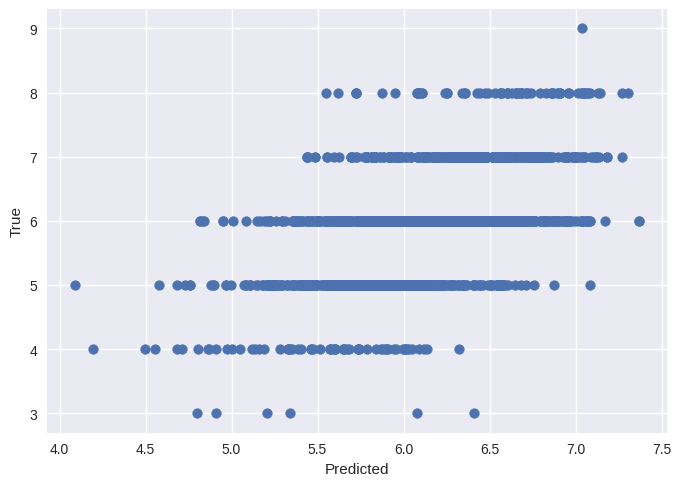

In [183]:
# After the training:

# Prepare scatter plot
y_pred = model.predict(X_test)[:,0]

print("Correlation coefficient:", np.corrcoef(y_pred,y_test)[0,1])
plt.scatter(y_pred,y_test)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [184]:
np.corrcoef(y_pred,y_test)

array([[1.        , 0.53468811],
       [0.53468811, 1.        ]])


# Problems

* Use the notebook as starting point. It already contains the simple network from Exercise 4.1 implemented in Keras.

* Currently, SGD is used without momentum. Try training with a momentum term. Replace SGD with the Adam optimizer and train using that. (See: https://keras.io/api/optimizers/)
* Add two more hidden layers to the network (you can choose the number of nodes but make sure to apply the ReLu activation function after each) and train again.
* Test differet numbers of examples (i.e. change the batch batch size) to be simulataneously used by the network.
* (bonus) optimize the network architecture to get the best correlation coefficient. (Let's see who gets the most out of the data).

**SGD**

In the project I changed the number of epochs to 20 to see how the results changed over more epochs. In the first part of the project the optimizer SGD was used without momentum.  
SGD stands for Stochastic Gradient Descent. The goal when training the network is to minimize the loss function. In this project the mean squared error is used for this. SGD the updates the weights in the direction that reduces the loss. The network consisted of 20 nodes with one hidden layer. This was the initial code with the modification of number of epochs.

For this optimizes the Correlation coefficient: 0.003516186582875353. Thus implying no correlation, and poor results. This method did not seem to work at all for the network. Plots showed no correlation what so ever.


**SGD with momentum**

Next momentum was added to the SGD. Momentum helps SGD move more consistently in directions where gradients repeatedly point the same way, and thus reduces oscillations. The learning rate was initially set to 0.00001 and it controls the size of each update and momentum was set to 0.9 and it controlls how strong influence the previous updates have on the next.

For this optimizer the Correlation coefficient: 0.48821851927696813. Which is a significant improvement from SGD with no momentum. This now indicates that there is some correlation between the features and the quality. It required some testing before the learning rate was sufficiently small. At first I set it to high which gave poor results.


**ADAM**

Next the optimizer was switched to the ADAM optimizer. Adam improves the syochastic gradient decent algorithm by using bouth momentum and adaptive learning rates, which updates the step size for each weight individually.

For this optimizer the Correlation coefficient: 0.5169360215998665

The correlation using Adam as optimizer showed to increase the correlation between features and quality. This is due to the adaption of learning rate which as I mentioned above strongly affects the convergence of the optimizer. When the learning rate was chosen to large no correlation could be found at all.



**Increasing number of layers**

In the next step I added two more layers to the neural network. The Correlation coefficient: 0.554822685747121. The added complexity of the network seemed to yielld even more accurate soultions with a higher correlation.

**Changing the batch size**

Finally the batch size was changed to 5 examples. Changing the batch size is a way of changing the way we train our data. Instead of training the entire data set per epoch we divide the data into 5 batches and then train for each batach and then uses these predictions to make an update. Changing the batch size can affect how efficiently and effectivly the neural networks learns. When using multiple batches the network calculated the avredge gradient from 5 samples instead of 1. This usually reduces randomness in each update.
When changing the batch size to 5 however the Correlation coefficient: 0.46133889922189664 had decreased.
The less noisy gradients eatimates obtained from using batches does not however not gurantee better predictions. However runtime was decreased significantly which can be an advantage when training large complex networks.



## SGD with momentum

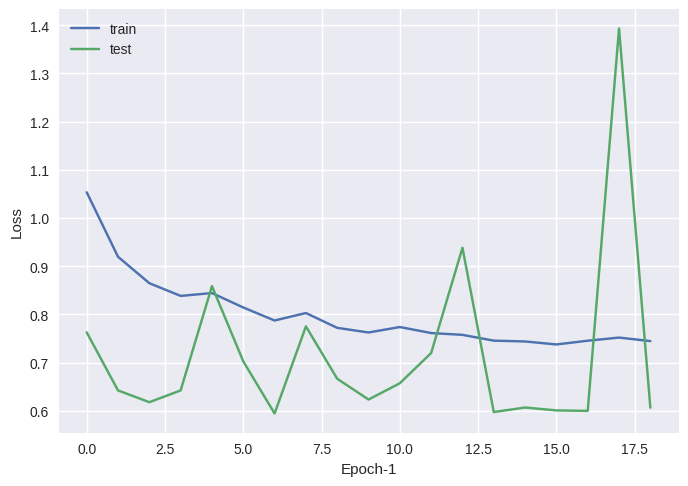

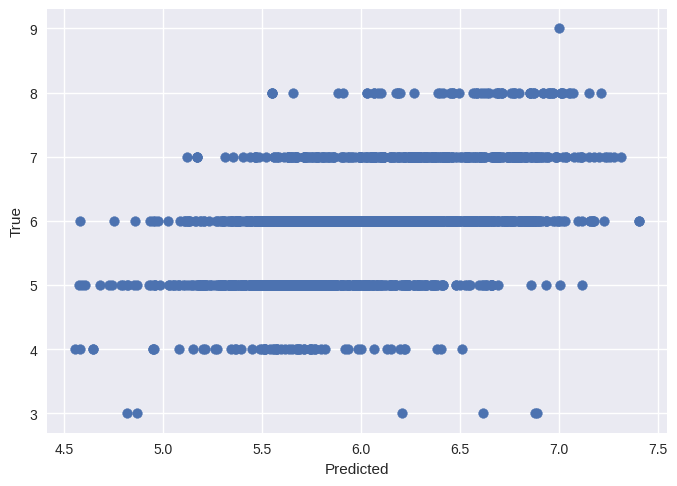

## ADAM

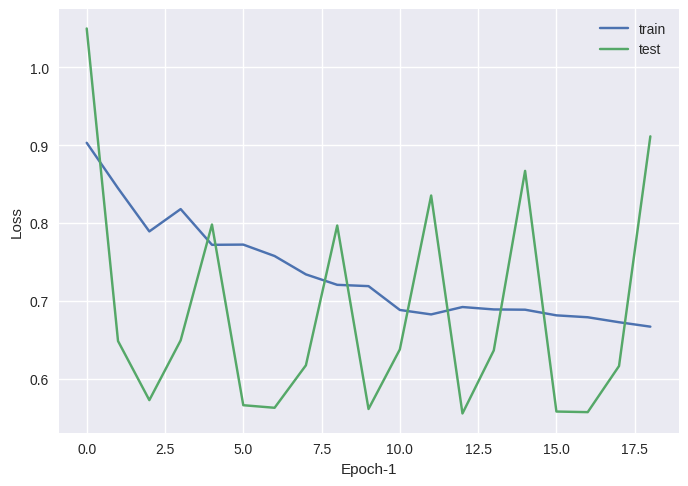

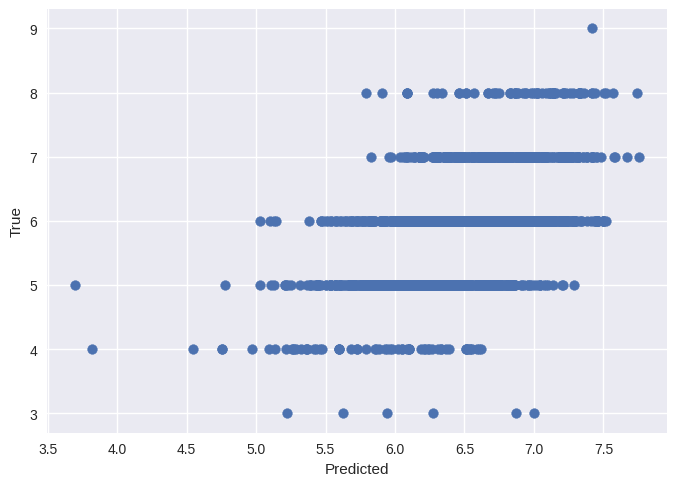

## Increasing number of layers

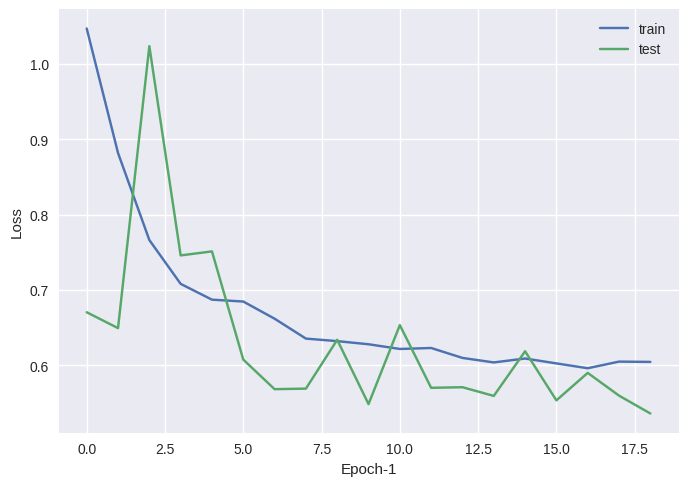

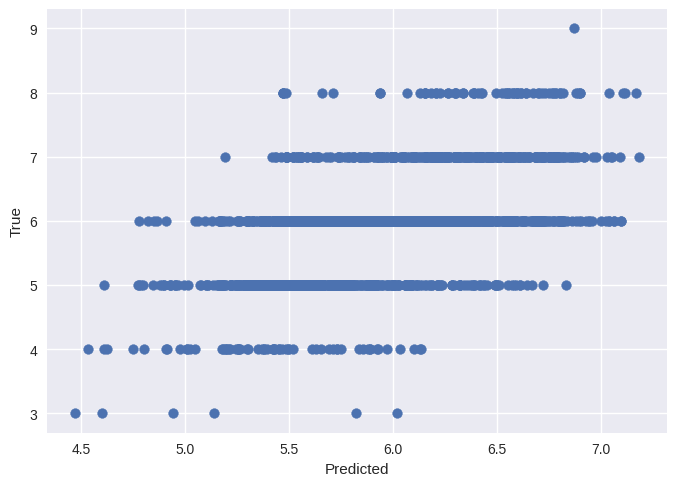

##Using 5 batches

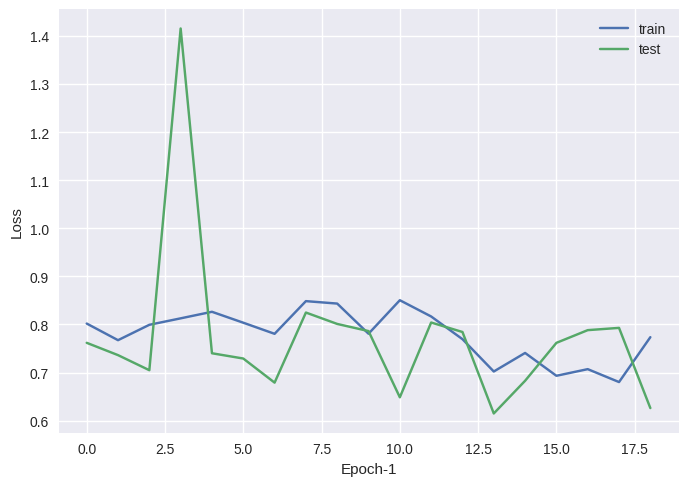

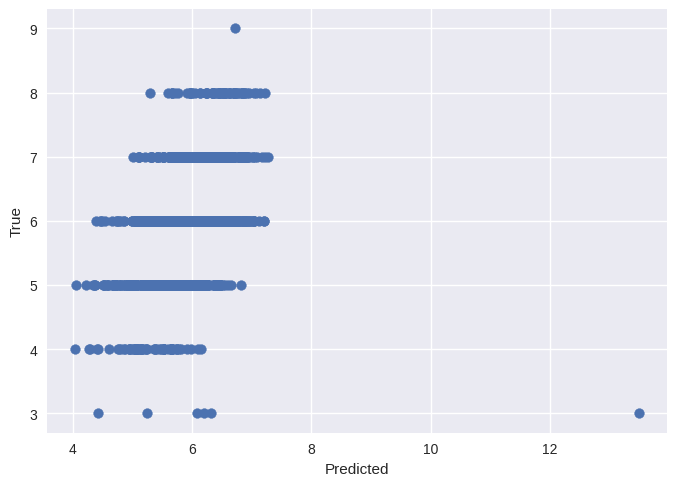